# Neural tabular model: MLP

A multilayer perceptron learns nonlinear relationships from scaled numeric features and one-hot categories. It avoids imposing a sequence on unrelated columns.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SMOKE = os.environ.get("HDB_SMOKE") == "1"
DATA = ROOT / ("tests/fixtures/transactions.csv" if SMOKE else "data/raw/resale.csv")
RUNS = Path(os.environ.get("HDB_RUN_ROOT", str(ROOT / "artifacts")))

import matplotlib.pyplot as plt
from IPython.display import display

print(f"Data: {DATA.name}; mode: {'synthetic smoke' if SMOKE else 'frozen snapshot'}")

Data: resale.csv; mode: frozen snapshot


## Optional experiment

Install `requirements-neural.txt` after the base requirements. Core baselines do not depend on PyTorch. We use bounded CPU runs for this portfolio; CUDA is optional. Target scaling is fitted only on training prices. Checkpoints use validation MAE, not training loss.

In [2]:
from hdb_resale.experiment import (
    evaluate_experiment,
    load_bundle,
    predict,
    train_experiment,
)

run = RUNS / "mlp"
if not (run / "metadata.json").exists():
    train_experiment(
        DATA, "mlp", run, epochs=2 if SMOKE else 20, threads=2, device="cpu"
    )
evaluate_experiment(run, DATA)

{'model': 'mlp',
 'split': 'test',
 'data_sha256': 'fb23b8460f1a762e4220382e91f3bfcf6030bb69286b1a5577646c33d7a608d1',
 'count': 5414,
 'mae_sgd': 32089.805899404324,
 'rmse_sgd': 44860.46216430734,
 'r2': 0.9483826946430451,
 'predict_seconds': 0.4176175000029616}

In [3]:
import pandas as pd

history = pd.read_csv(run / "history.csv")
history

,epoch,train_mse_scaled,validation_mae_sgd
0,1,0.200516,37742.411336
1,2,0.051358,32545.233695
2,3,0.045647,29410.653538
3,4,0.042423,28275.214397
4,5,0.040695,27961.477325
5,6,0.039433,27758.024946
6,7,0.038336,27592.827643
7,8,0.037574,28713.073378
8,9,0.036784,27129.833145
9,10,0.036373,28904.518718


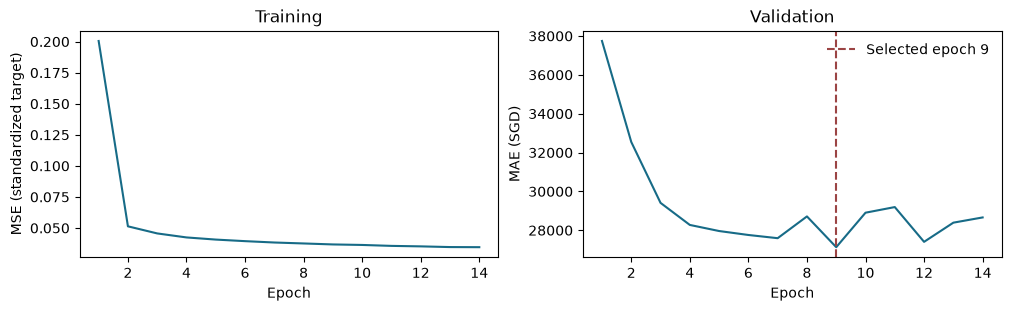

In [4]:
from hdb_resale.plots import plot_learning_curve

figure = plot_learning_curve(history)
display(figure)
plt.close(figure)

Training loss uses standardized target MSE; validation uses MAE in SGD. Their magnitudes are not directly comparable. The dashed line marks the checkpoint selected by validation, which may precede the last epoch.

## Checkpoint selection

The saved weights belong to the epoch with lowest validation MAE. The standardised target is converted back to SGD using training-only statistics. CPU inference reconstructs the network from a state dictionary rather than unpickling a notebook-defined model class.

In [5]:
from hdb_resale.data import load_data

sample = load_data(DATA).tail(3).drop(columns="resale_price")
sample.assign(predicted_price_sgd=predict(load_bundle(run), sample))

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,predicted_price_sgd
202396,2025-01-01,YISHUN,EXECUTIVE,836,YISHUN ST 81,01 TO 03,146.0,Maisonette,1988,62 years 02 months,907457.250
202397,2025-02-01,YISHUN,EXECUTIVE,824,YISHUN ST 81,01 TO 03,145.0,Apartment,1987,61 years 10 months,886881.375
202398,2025-02-01,YISHUN,EXECUTIVE,826,YISHUN ST 81,10 TO 12,146.0,Maisonette,1988,62 years,964799.375


## Test error analysis

The diagonal marks perfect predictions; darker hexagons contain more transactions. Residuals are predicted minus actual SGD, so negative values mean underprediction. Read subgroup MAE with its count: small groups give unstable estimates. These final diagnostics describe limitations and do not trigger test-driven retuning.

Test diagnostics: mlp


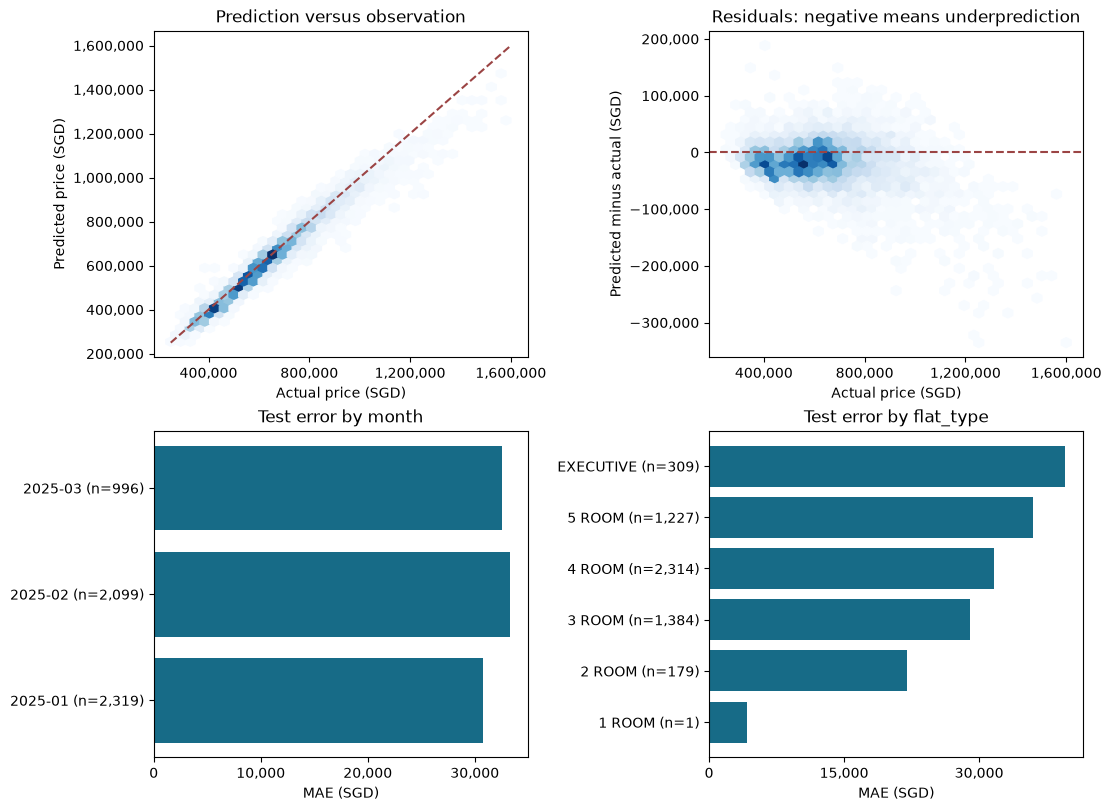

In [6]:
import pandas as pd

from hdb_resale.plots import plot_diagnostics

diagnostic_runs = [run]
for diagnostic_run in diagnostic_runs:
    predictions = pd.read_csv(diagnostic_run / "test_predictions.csv")
    groups = pd.read_csv(diagnostic_run / "test_groups.csv")
    print(f"Test diagnostics: {diagnostic_run.name}")
    figure = plot_diagnostics(predictions, groups)
    display(figure)
    plt.close(figure)

## Configuration

Hidden layers of 128 and 64 units, ReLU, dropout 0.1, Adam at 0.001, batch size 1024, maximum 20 epochs, and patience 5. No hyperparameter sweep. Compare its validation MAE and runtime with trees before arguing that neural complexity is useful.